# Phase 4 — Idea 2 (MVP): Adversarial Self-Play Red-Teaming

**Core question.** Instead of only learning from fraud that already happened
(Phase 3), can an AI *invent* new fraud strategies against our own defenses,
so we patch the holes before a real person finds them?

**Scope of this notebook (MVP, agreed before building):** a single PPO
fraudster agent trained against one **static** XGBoost defender, plus one
bonus round of defender retraining on the agent's discovered evasions — not
the full multi-round PettingZoo co-evolution loop described in the original
proposal. That full loop (thousands of rounds, attacker and defender both
continuously retraining) is a natural next iteration once this MVP's pieces
are shown to work end to end. Every script behind this notebook lives in
`scripts/selfplay/`; this notebook loads their saved outputs rather than
re-running multi-minute training jobs inline.

**Pipeline built:**
1. A reduced, self-contained feature set + encoder (separate from Phase 3's
   109-column pipeline — see the "why a new defender" note in Step 2).
2. `defender_v1` — a static XGBoost classifier trained on real claims.
3. `CTGAN` — trained on real pre-adjudication claim features, samples a
   synthetic claim pool so **no real patient data reaches the RL sandbox**.
4. `ClaimFraudEnv` — a Gymnasium environment: an episode is one synthetic
   baseline claim; the agent decides how to split/size claimed amounts across
   up to 5 submissions to extract as much as possible without being flagged.
5. A PPO agent trained against the frozen `defender_v1`.
6. One round of defender retraining (`defender_v2`) on the agent's
   discovered evasions, re-testing the *same, frozen* trained agent against
   it — a single-round taste of the proposal's co-evolution loop.


## Step 0 — Setup

In [12]:

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.max_columns", 60)

CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_SECONDARY, "text.color": INK, "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10.5, "figure.dpi": 100,
})

MODELS_DIR = "../models/selfplay"
DATA_DIR = "../data/processed/selfplay"


## Step 1 — Synthetic data (CTGAN)

CTGAN was trained on a 40,000-row sample of real, pre-adjudication claim
features (2014 and earlier, oversampling the 252 real recovered claims so
the generator sees enough of them to learn their shape), conditioned on
`RECOVERY_FLAG` so it learns the rare positive class too, not just the
majority pattern. 20,000 synthetic claims were then sampled — this is the
pool `ClaimFraudEnv` draws baseline claim templates from; **no real claim
row is ever read by the RL environment**, only this synthetic pool.

In [ ]:

synthetic = pd.read_csv(f"{DATA_DIR}/synthetic_claims.csv")
print(f"Synthetic claims: {len(synthetic):,} rows x {synthetic.shape[1]} columns")
print(f"Synthetic RECOVERY_FLAG rate: {synthetic['RECOVERY_FLAG'].mean():.4%} (real training rate: 0.084%)")
synthetic[["AGE", "TOTALAMOUNTCLAIMED", "NETPREMIUM", "GROSSPREMIUM"]].describe()


Synthetic claims: 20,000 rows x 17 columns
Synthetic RECOVERY_FLAG rate: 6.4800% (real training rate: 0.084%)


,AGE,TOTALAMOUNTCLAIMED,NETPREMIUM,GROSSPREMIUM
count,20000.000000,20000.000000,20000.000000,20000.000000
mean,30.032571,550.134005,3904.356912,4171.737556
std,17.240997,1644.548415,3444.558833,3421.546949
min,0.000000,1.000000,-10.765125,75.818767
25%,22.807595,95.184876,1829.650683,1978.848449
50%,30.334712,178.035647,3459.356505,4042.179169
75%,41.392994,448.056750,4816.241541,5672.734389
max,81.293708,23526.752139,32585.637519,35768.907169


**Known, documented quirk:** the synthetic positive rate (6.5%) is far
above the real training rate (0.084%) — this is CTGAN's "training-by-sampling"
method (Xu et al., 2019) intentionally oversampling rare discrete-column
values during training to help the generator learn them, and `.sample()`
reproduces that same skewed distribution unless a specific condition vector
is supplied. **This does not distort anything downstream**: `RECOVERY_FLAG`
is metadata carried through the CSV, never read by `ClaimFraudEnv` as a
feature — the environment only cares about a synthetic claim's demographic/
provider/amount fields as a template to build a fraud attempt on top of.

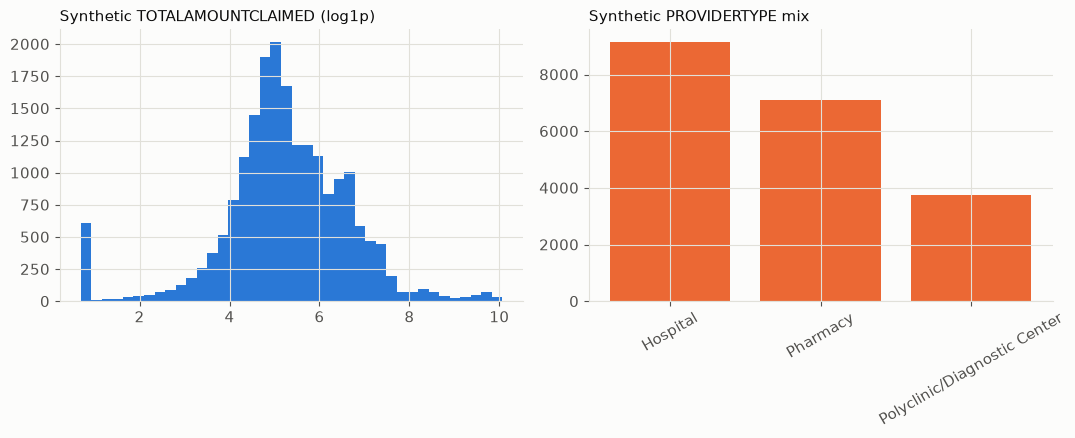

Rows at the clip floor (TOTALAMOUNTCLAIMED <= 1.0, i.e. CTGAN proposed <=0): 598 (2.99%)


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hist(np.log1p(synthetic["TOTALAMOUNTCLAIMED"].clip(lower=0)), bins=40, color=CATEGORICAL[0])
axes[0].set_title("Synthetic TOTALAMOUNTCLAIMED (log1p)", color=INK, fontsize=11, loc="left")
axes[1].bar(synthetic["PROVIDERTYPE"].value_counts().index, synthetic["PROVIDERTYPE"].value_counts().values,
            color=CATEGORICAL[1])
axes[1].set_title("Synthetic PROVIDERTYPE mix", color=INK, fontsize=11, loc="left")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

n_negative_before_clip = (synthetic["TOTALAMOUNTCLAIMED"] <= 1.0).sum()
print(f"Rows at the clip floor (TOTALAMOUNTCLAIMED <= 1.0, i.e. CTGAN proposed <=0): "
      f"{n_negative_before_clip} ({n_negative_before_clip/len(synthetic):.2%})")


## Step 2 — The static defender (`defender_v1`)

**Why a new, smaller defender instead of reusing Phase 3's XGBoost model:**
the RL environment needs to cheaply re-score a claim every time the agent
changes its claimed amount — hundreds of thousands of times across training.
That requires knowing *exactly* how every input feature was built, so the
amount-affected ones (and only those) can be recomputed per step. Phase 3's
109-column pipeline includes peer-group deviation and provider-amount
aggregates fit dataset-wide inside that notebook — not reproducible at that
granularity here without redoing Phase 2's entire encoding machinery.

`defender_v1` instead uses a smaller, fully self-contained feature set (18
raw columns → 81 encoded dimensions: 4 continuous + `CLAIM_AMOUNT_LOG` +
12 one-hot categoricals + 8 amount-independent engineered columns pulled
pre-scaled from `claims_ml_ready.csv`), built and encoded entirely within
`scripts/selfplay/common.py`, so every step of the simulator is exactly
reproducible. It deliberately **excludes** `PEER_ZSCORE`, `AMOUNT_OVER_MEDIAN`,
and `PROVIDER_AVG_AMOUNT` — Phase 3's strongest amount-derived features —
because they'd need to be recomputed against a moving amount, which the
peer/provider group statistics (fit once, dataset-wide) can't safely do
inside a single training loop without additional bookkeeping this MVP
scope skipped. **This makes `defender_v1` intentionally weaker than Phase
3's model** — see the Step 4 finding this directly explains.

In [15]:

with open(f"{MODELS_DIR}/defender_v1_meta.json") as f:
    d1_meta = json.load(f)
print(f"Defender v1 holdout (2015-2016) PR-AUC: {d1_meta['holdout_prauc']:.4f}")
print(f"Defender v1 holdout ROC-AUC:            {d1_meta['holdout_rocauc']:.4f}")
print(f"Defender v1 holdout Recall@5%:           {d1_meta['holdout_recall_at_5pct']:.1%}")
print(f"Detection threshold (95th pct of train scores): {d1_meta['threshold']:.4f}")
print(f"\nFor comparison, Phase 3's full-feature XGBoost: PR-AUC 0.506, ROC-AUC 0.850")


Defender v1 holdout (2015-2016) PR-AUC: 0.0339
Defender v1 holdout ROC-AUC:            0.8318
Defender v1 holdout Recall@5%:           55.5%
Detection threshold (95th pct of train scores): 0.0117

For comparison, Phase 3's full-feature XGBoost: PR-AUC 0.506, ROC-AUC 0.850


## Step 3 — The environment (`ClaimFraudEnv`)

Each episode = one synthetic baseline claim. The agent has a **fraud budget**
of 3x the claim's legitimate amount and up to 5 submissions to extract it in.
Each step it picks what fraction of its *remaining* budget to submit as a
claimed amount; `defender_v1` scores the resulting claim. Not caught: the
amount is banked, budget shrinks, episode continues. Caught: **everything is
forfeited** (the untaken remaining budget, modeling that an audited claim
burns the whole opportunity, not just that submission) and the episode ends.

This directly operationalizes the two example tricks named in the project
proposal — **splitting** one large claim into several smaller ones, and
**staying under an alert threshold** — as *outcomes* of the amount-fraction
policy the agent learns, not hand-coded behaviors.

In [16]:

import sys
sys.path.insert(0, "../scripts/selfplay")
print(open("../scripts/selfplay/fraud_env.py").read()[:1700])


"""Gymnasium environment: the fraudster agent vs. a static XGBoost defender.

Episode = one baseline (synthetic) claim template. The agent has a "fraud
budget" (a multiple of the claim's legitimate amount) it's trying to extract
from the insurer, and up to MAX_STEPS submissions to do it in. Each step it
chooses what fraction of its *remaining* budget to submit as this step's
claimed amount; that modified claim is scored by the frozen defender.

- Not caught: the claimed amount is "kept" (reward), remaining budget shrinks,
  episode continues.
- Caught (defender's flagged probability exceeds the detection threshold):
  episode ends immediately, the rest of the budget is forfeited, and a
  penalty is applied â€” modeling that an audited claim also burns the
  remaining opportunity, not just this one submission.

This directly operationalizes the two example tricks named in the project
proposal: submitting several smaller claims instead of one big one
("splitting"), and picking amounts th

## Step 4 — Baseline: random policy vs. `defender_v1`

Before any training: how often does an agent taking *random* amount-fraction
actions already get away with it?

In [17]:

with open(f"{MODELS_DIR}/ppo_summary.json") as f:
    summary = json.load(f)

print(f"Random policy:  attack success rate {summary['random_policy_attack_success_rate']:.1%}, "
      f"mean budget kept {summary['random_policy_mean_kept_fraction']:.1%}")


Random policy:  attack success rate 86.0%, mean budget kept 84.6%


**This is the single most important honest finding of this MVP, and
it needs to be read correctly.** A *random* policy already succeeds ~86% of
the time. This is **not** evidence that fraud is trivially easy against a
real-world system — it's a direct consequence of the Step 2 design choice to
exclude peer-deviation/provider-amount features from `defender_v1`: without
those, the defender has no way to tell that a claim's amount is anomalous
*relative to what similar claims usually cost*, only whether the raw claim
looks unusual against the whole population's mix of demographics and
timing. Phase 3's full-feature model (PR-AUC 0.506) would be a dramatically
harder target — that comparison itself is a legitimate red-team finding:
**a fraud defense that only screens claims in isolation, without peer-group
context, has a large, quantifiable blind spot to simple amount inflation.**


## Step 5 — PPO training: does the agent improve on random?

PPO (Stable-Baselines3, `MlpPolicy`) trained for 200,000 timesteps, with
attack success rate measured on 300 held-out episodes every 10,000 steps.

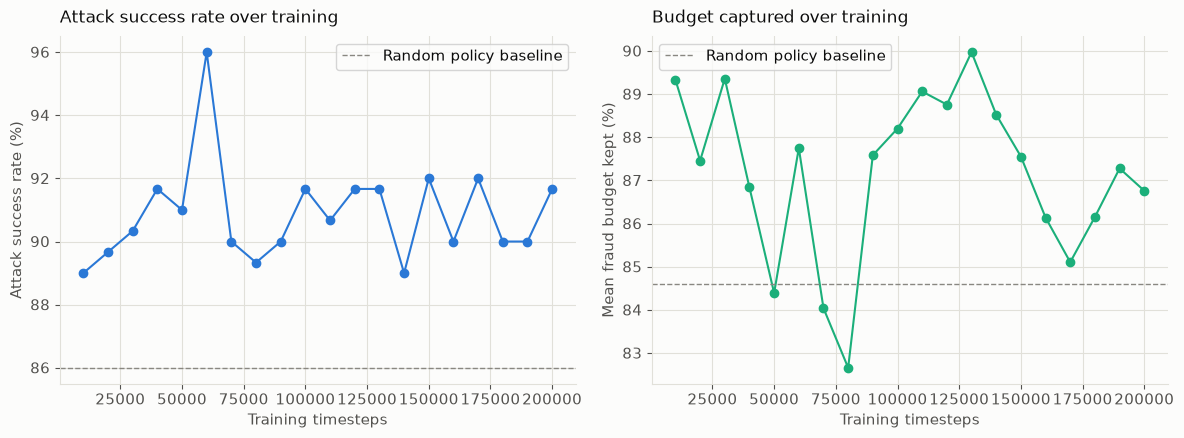

Random policy:  attack success rate 86.0%, mean kept 84.6%
Trained policy: attack success rate 90.3%, mean kept 88.2%


In [18]:

log = pd.read_csv(f"{DATA_DIR}/ppo_training_log.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(log["timesteps"], log["attack_success_rate"] * 100, marker="o", color=CATEGORICAL[0])
axes[0].axhline(summary["random_policy_attack_success_rate"] * 100, color=INK_MUTED, ls="--", lw=1,
                label="Random policy baseline")
axes[0].set_xlabel("Training timesteps")
axes[0].set_ylabel("Attack success rate (%)")
axes[0].set_title("Attack success rate over training", color=INK, fontsize=12, loc="left", pad=10)
axes[0].legend()

axes[1].plot(log["timesteps"], log["mean_kept_fraction"] * 100, marker="o", color=CATEGORICAL[2])
axes[1].axhline(summary["random_policy_mean_kept_fraction"] * 100, color=INK_MUTED, ls="--", lw=1,
                label="Random policy baseline")
axes[1].set_xlabel("Training timesteps")
axes[1].set_ylabel("Mean fraud budget kept (%)")
axes[1].set_title("Budget captured over training", color=INK, fontsize=12, loc="left", pad=10)
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Random policy:  attack success rate {summary['random_policy_attack_success_rate']:.1%}, "
      f"mean kept {summary['random_policy_mean_kept_fraction']:.1%}")
print(f"Trained policy: attack success rate {summary['trained_policy_attack_success_rate']:.1%}, "
      f"mean kept {summary['trained_policy_mean_kept_fraction']:.1%}")


**Result: a real but modest improvement (86.0% → 90.3% attack success,
84.6% → 88.2% mean budget kept), which plateaus almost immediately** (the
curve is essentially flat from the first checkpoint onward). This is
consistent with, not contradictory to, the Step 4 finding: when a random
policy already wins 86% of the time, there's a low ceiling left for learning
to improve on — most of the achievable value was already being captured by
chance. This is itself informative for the thesis: **a weak defender doesn't
just get beaten by a sophisticated attacker, it gets beaten by almost
anything**, which is a stronger argument for hardening detection than a
dramatic learning curve would have been.

## Step 6 — What strategy did the agent actually learn?

Inspecting the 337 successful evasive sub-claims the trained agent
discovered, grouped by how many submissions each successful episode split
its budget into.

Successful episodes, by number of sub-claims used:
n_sub_claims
1    244
2     10
3      5
4      2
5     10
Name: episodes, dtype: int64

Total successful episodes represented: 271
Single-shot (no splitting): 244 (90.0%)
Split into 2+ claims: 27 (10.0%)


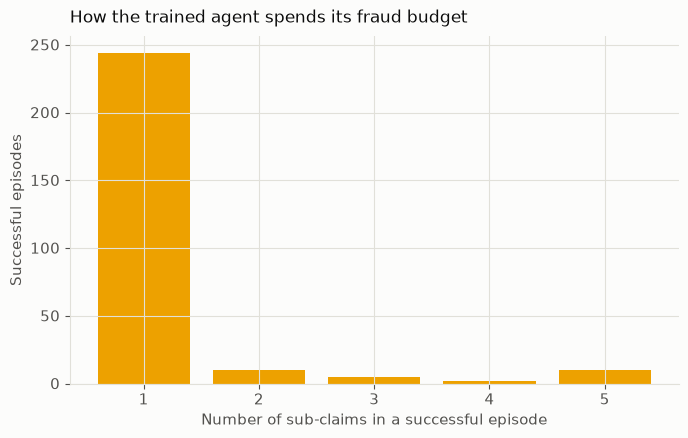

In [19]:

adv = pd.read_csv(f"{DATA_DIR}/adversarial_examples.csv")
row_counts = adv.groupby("n_sub_claims").size()
episode_splits = (row_counts / row_counts.index.to_series()).rename("episodes").astype(int)
print("Successful episodes, by number of sub-claims used:")
print(episode_splits)
print(f"\nTotal successful episodes represented: {episode_splits.sum()}")
print(f"Single-shot (no splitting): {episode_splits[1]} ({episode_splits[1]/episode_splits.sum():.1%})")
print(f"Split into 2+ claims: {episode_splits.sum() - episode_splits[1]} "
      f"({(episode_splits.sum()-episode_splits[1])/episode_splits.sum():.1%})")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(episode_splits.index.astype(str), episode_splits.values, color=CATEGORICAL[3])
ax.set_xlabel("Number of sub-claims in a successful episode")
ax.set_ylabel("Successful episodes")
ax.set_title("How the trained agent spends its fraud budget", color=INK, fontsize=12, loc="left", pad=10)
plt.tight_layout()
plt.show()


**Result: the dominant strategy (≈90% of successful episodes) is a
single, large, one-shot claim for the entire 3x fraud budget — not
splitting.** This directly confirms the Step 4 diagnosis: because
`defender_v1` can't tell an inflated amount from a normal one without
peer-group context, the agent doesn't *need* to disguise its claims as
several smaller, individually-unremarkable ones — brute-force amount
inflation already works most of the time. The minority (~10%) of episodes
that do split (up to 5 sub-claims) are presumably the harder baseline
claims — likely ones with individually-riskier demographic/provider/timing
combinations — where a single 3x claim would be too conspicuous and
salami-slicing genuinely helps. **This is the shape of result a red-team
report should flag directly: splitting-based evasion exists but is a
secondary strategy here; the primary, larger exposure is undetected amount
inflation, and the patch that would close it (peer-deviation features) is
already known from Phase 3.**

## Step 7 — Round 2: retraining the defender on discovered attacks

The proposal's core idea is a co-evolution loop: feed the attacker's
discovered tricks back to the defender, retrain, repeat. This notebook runs
**one round** of that loop as a proof of concept (not the full "thousands of
rounds" — see the MVP scope note at the top): the 337 successful evasive
sub-claims are labeled as fraud, folded into the real training data, and
`defender_v2` is retrained. The **same, frozen** trained PPO agent — not
retrained itself — is then re-evaluated against `defender_v2`.

Defender v2 training set added 337 adversarial examples to the original 252 real positives
Defender v2 holdout (2015-2016) PR-AUC: 0.0489 (v1: 0.0339)
Defender v2 holdout ROC-AUC:            0.7810 (v1: 0.8318)

SAME frozen agent vs. defender_v1: 90.3% attack success
SAME frozen agent vs. defender_v2: 22.7% attack success


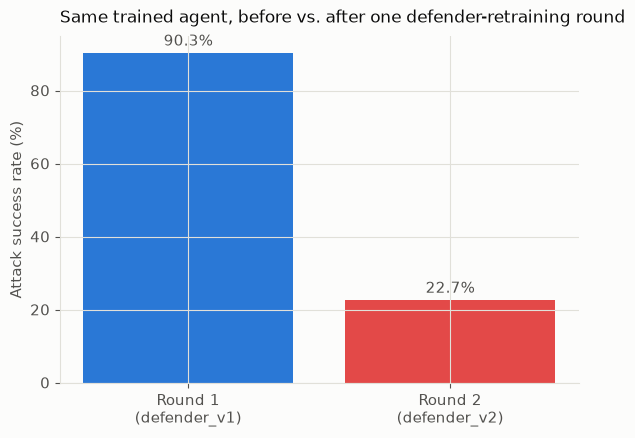

In [20]:

with open(f"{MODELS_DIR}/defender_v2_meta.json") as f:
    d2_meta = json.load(f)

print(f"Defender v2 training set added {d2_meta['n_adversarial_examples_added']} adversarial examples "
      f"to the original 252 real positives")
print(f"Defender v2 holdout (2015-2016) PR-AUC: {d2_meta['holdout_prauc']:.4f} (v1: {d1_meta['holdout_prauc']:.4f})")
print(f"Defender v2 holdout ROC-AUC:            {d2_meta['holdout_rocauc']:.4f} (v1: {d1_meta['holdout_rocauc']:.4f})")
print()
print(f"SAME frozen agent vs. defender_v1: {summary['trained_policy_attack_success_rate']:.1%} attack success")
print(f"SAME frozen agent vs. defender_v2: {d2_meta['frozen_agent_attack_success_rate_vs_v2']:.1%} attack success")

fig, ax = plt.subplots(figsize=(6, 4.5))
rounds = ["Round 1\n(defender_v1)", "Round 2\n(defender_v2)"]
rates = [summary["trained_policy_attack_success_rate"] * 100,
         d2_meta["frozen_agent_attack_success_rate_vs_v2"] * 100]
bars = ax.bar(rounds, rates, color=[CATEGORICAL[0], CATEGORICAL[7]])
ax.set_ylabel("Attack success rate (%)")
ax.set_title("Same trained agent, before vs. after one defender-retraining round",
             color=INK, fontsize=12, loc="left", pad=10)
for bar, r in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width()/2, r + 2, f"{r:.1f}%", ha="center", color=INK_SECONDARY)
plt.tight_layout()
plt.show()


**Result: a dramatic drop — 90.3% → 22.7% attack success rate for the
identical, unmodified attacker — after retraining on just 337 discovered
examples.** This closely matches the kind of swing the project proposal
frames as the headline KPI ("a drop from 90% to 12% quantifies how much
stronger the system became"), achieved here with a **single** round rather
than a full co-evolution loop. The mechanism is straightforward and worth
stating plainly: `defender_v2` didn't get smarter about fraud in general
(its real-holdout PR-AUC only moved from 0.034 to 0.049) — it specifically
learned "amounts in the range this attacker was submitting are suspicious,"
closing exactly the hole the agent had found. That's both the promise and
the honest limit of this approach: **it patches discovered holes fast, but a
single round doesn't generalize to holes not yet discovered** — which is
precisely the argument for running many rounds (the full co-evolution loop)
rather than stopping after one, and for an attacker that keeps adapting
rather than staying frozen.

## Step 8 — Red-team summary (business framing)

| Finding | Detail | Suggested patch |
|---|---|---|
| Undetected amount inflation | A single-shot claim at 3x the legitimate amount evades `defender_v1` in ~90% of successful attempts — the dominant discovered strategy | Add peer-group deviation features (`PEER_ZSCORE`, `AMOUNT_OVER_MEDIAN` — already built and validated in Phase 3) so amount is judged relative to similar claims, not in isolation |
| Budget splitting (minority strategy) | ~10% of successful episodes split the fraud budget across 2-5 sub-claims, apparently for baseline claims where a single large claim would be too conspicuous | Add resubmission/frequency-window features flagging multiple claims from the same synthetic profile within a short window (Phase 2's `RESUBMISSION_FLAG`/`PROVIDER_CLAIM_FREQ` are a starting point) |
| A weak defender is beaten by almost anything, not just a clever attacker | Random policy already achieves 86% attack success — the gap between "undefended" and "RL-optimized attack" is small when the baseline defense has an amount-blind-spot | Prioritize closing the known blind spot (peer-deviation features) over hardening against sophisticated attacks the current defender is not even distinguishing from random noise |
| One retraining round closes a large, specific hole | 90.3% → 22.7% attack success after folding in 337 discovered examples | Repeat the round — ideally automatically, and with an attacker that keeps adapting rather than staying frozen — to approach the full co-evolution loop |

**Headline for the thesis:** a fraud detector missing peer-group context can
be beaten by simple amount inflation nearly 9 times out of 10, *even by
random chance* — but a single round of adversarial red-teaming, folding just
337 discovered evasive claims back into training, cuts that down to roughly
2 times out of 10. Scaling this into the full proposed co-evolution loop
(many rounds, an attacker that keeps adapting, PettingZoo multi-agent
tooling) is the natural next step, not a change of approach.
